In [70]:
# lets get started with single image
image_path = "../archive/frames"
import os
# sample random image from the folder
import random
from IPython.display import display
from PIL import Image
import time
from ultralytics import YOLO
import pandas as pd
import torch
from torchvision import transforms
import matplotlib.pyplot as plt
import cv2
from PIL import ImageDraw


%matplotlib inline



In [36]:
all_image_files = [os.path.join(image_path, f) for f in os.listdir(image_path) if f.endswith(".jpg")]
sample_image_file = random.choice(all_image_files)
subset_image_files = all_image_files[:20]  # taking first 10 images for testing

In [37]:

# time to run the model on the image

model = YOLO("yolov8n.pt")
# start_time = time.time()
# results = model(all_image_files[:10])
# end_time = time.time()
# print(f"Inference time: {end_time - start_time} seconds")   

# Lets make an empty list and apply the model on all images and store the results in the list
all_results = []
for img_file in subset_image_files:
    results = model(img_file, verbose=False)
    all_results.append([results, img_file])

In [43]:
# Lets store all the bboxes in a pandas dataframe for further processing only keeping the persons detected
all_detections = []
for result in all_results:
    boxes = result[0][0].boxes
    for box in boxes:
        bbox = box.xyxy[0].cpu().numpy()
        conf = box.conf[0].cpu().numpy()
        cls = box.cls[0].cpu().numpy()
        path_of_image = result[1]
        all_detections.append({
            "xmin": bbox[0],
            "ymin": bbox[1],
            "xmax": bbox[2],
            "ymax": bbox[3],
            "confidence": conf,
            "class": cls,
            "image_path": path_of_image
        })
df_detections = pd.DataFrame(all_detections)
# only keep persons (class 0)
df_detections = df_detections[df_detections["class"] == 0]


In [45]:
df_detections.head()

,xmin,ymin,xmax,ymax,confidence,class,image_path
0,1696.411011,298.038879,1835.033936,579.928345,0.83696574,0.0,../archive/frames/c5s1_067023.jpg
1,1158.350220,332.113464,1214.699097,495.463531,0.73827434,0.0,../archive/frames/c5s1_067023.jpg
2,355.437286,343.482239,438.214508,517.090393,0.7248444,0.0,../archive/frames/c5s1_067023.jpg
3,475.557037,353.948212,512.741333,436.783661,0.7022783,0.0,../archive/frames/c5s1_067023.jpg
5,771.640015,338.984070,820.678589,453.393768,0.5346872,0.0,../archive/frames/c5s1_067023.jpg


In [53]:
# now since we have detected people in the image, we can now proceed by getting their embeddings using a pre-trained model like OpenPose or any other model of your choice. so pass
#  the bounding boxes to the model and get the embeddings for each person detected in the image.
#  we can use resnet for this purpose.

model = torch.hub.load('pytorch/vision:v0.10.0', 'resnet50', pretrained=True)
model.eval()
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

embeddings = []
for _, row in df_detections.iterrows():
    x1, y1, x2, y2 = int(row["xmin"]), int(row["ymin"]), int(row["xmax"]), int(row["ymax"])
    image = Image.open(row["image_path"]).convert("RGB")
    person_img = image.crop((x1, y1, x2, y2))
    input_tensor = preprocess(person_img)
    input_batch = input_tensor.unsqueeze(0)  # create a mini-batch as expected by the model
    with torch.no_grad():
        output = model(input_batch)
    embeddings.append([output[0].cpu().numpy(), row["image_path"], (x1, y1, x2, y2)])



Using cache found in /home/saad/.cache/torch/hub/pytorch_vision_v0.10.0
/home/saad/anaconda3/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/saad/anaconda3/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [58]:
# Now embeddings is a list of [embedding vector, image path, bounding box]

In [88]:
query_image_path = "../archive/query_box/929_c4s4_070816.jpg"
query_image = Image.open(query_image_path).convert("RGB")
input_tensor = preprocess(query_image)
input_batch = input_tensor.unsqueeze(0)  # create a mini-batch as expected by
# the model
with torch.no_grad():
    query_output = model(input_batch)
    query_embedding = query_output[0].cpu().numpy()
# now we have the query embedding, we can now compare it with the embeddings of the detected persons in the images using cosine similarity
from sklearn.metrics.pairwise import cosine_similarity
similarities = []
for emb in embeddings:
    sim = cosine_similarity([query_embedding], [emb[0]])[0][0]
    similarities.append([sim, emb[1], emb[2]])  # similarity, image path, bounding box
# now we can sort the similarities and get the top 5 matches
similarities.sort(key=lambda x: x[0], reverse=True)
top_5_matches = similarities[:5]

In [89]:
for result in results:
    result.show()
for match in top_5_matches:
    image = Image.open(match[1]).convert("RGB")
    draw = ImageDraw.Draw(image)
    x1, y1, x2, y2 = match[2]
    draw.rectangle([x1, y1, x2, y2], outline="red", width=3)

    # display(image)

/usr/bin/eog: symbol lookup error: /snap/core20/current/lib/x86_64-linux-gnu/libpthread.so.0: undefined symbol: __libc_pthread_init, version GLIBC_PRIVATE


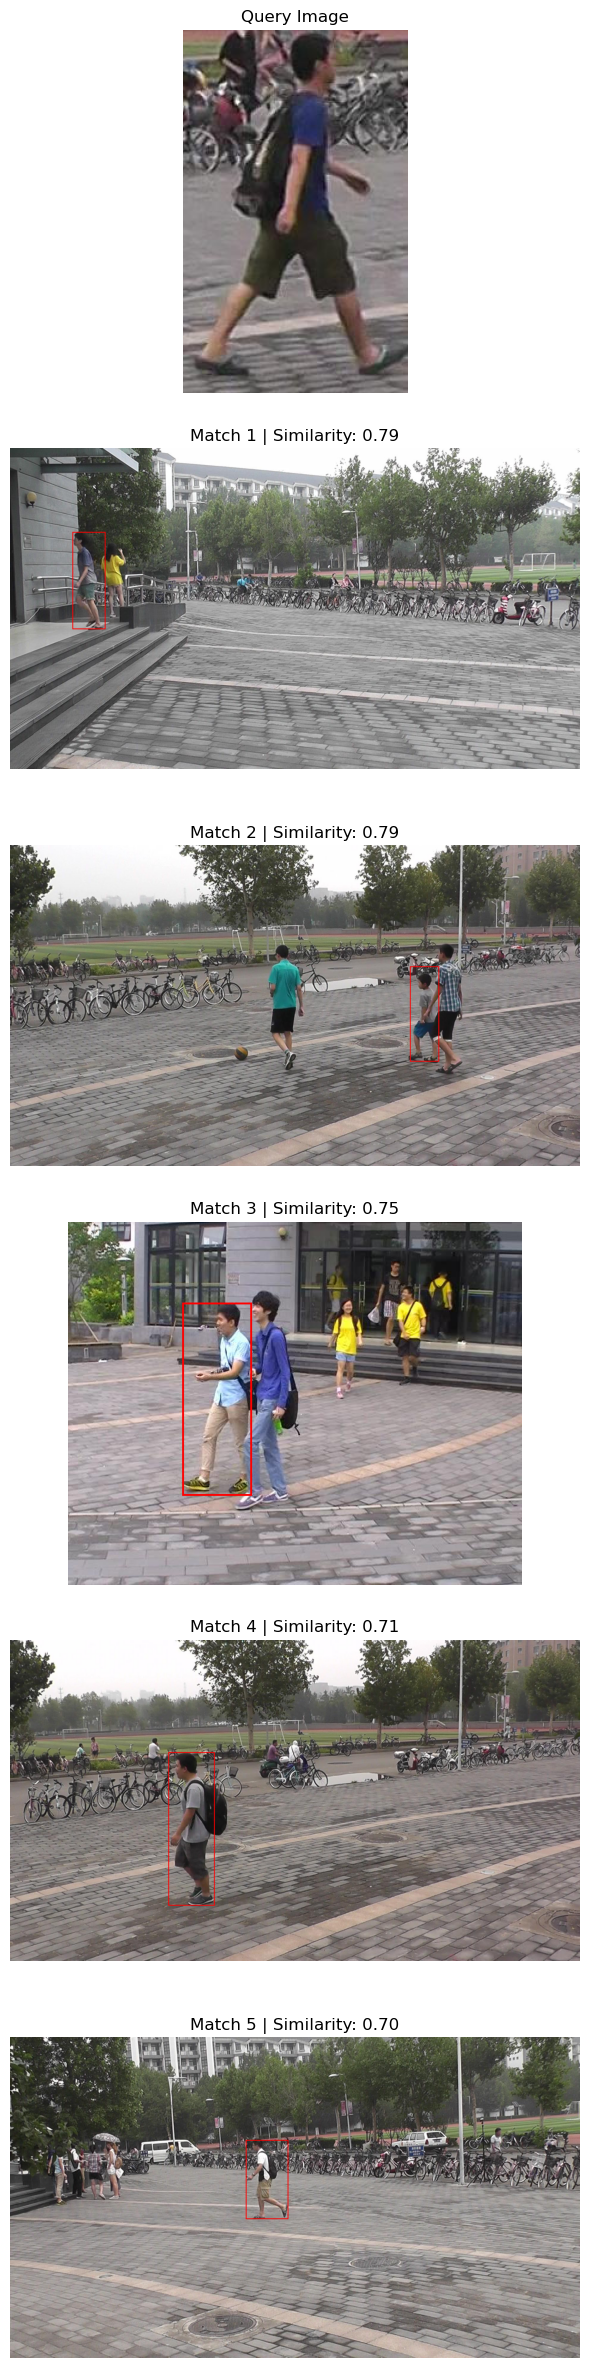

In [90]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# total rows = 1 query + top-5 matches
fig, axs = plt.subplots(6, 1, figsize=(6, 24))

# ---- Query image (row 0) ----
axs[0].imshow(query_image)
axs[0].set_title("Query Image")
axs[0].axis("off")

# ---- Top-5 matches (one per row) ----
for i, match in enumerate(top_5_matches):
    image = Image.open(match[1]).convert("RGB")
    draw = ImageDraw.Draw(image)

    x1, y1, x2, y2 = match[2]
    draw.rectangle([x1, y1, x2, y2], outline="red", width=3)

    axs[i + 1].imshow(image)
    axs[i + 1].set_title(f"Match {i + 1} | Similarity: {match[0]:.2f}")
    axs[i + 1].axis("off")

plt.tight_layout()
plt.show()
